# 02 – H3 Hexagon Grid

Covers the city with a grid of equal-sized hexagons using Uber's H3 system. Each
hexagon becomes one candidate location, so features like population, competitors,
and transit access can be attached to the same unit and compared fairly.

**Why hexagons?** Census areas and neighbourhoods vary widely in shape and size, which
makes them hard to compare. Hexagons are uniform, and every neighbour is the same
distance from the center, which makes them well suited for distance-based analysis.

**Why resolution 8?** Each hexagon covers roughly 0.7–0.8 km², about a 5–10 minute
walk across, which is the right scale for comparing potential store locations.

**Notes**
- H3 works in latitude/longitude (EPSG:4326), so the boundary is converted back
  before generating cells, then the grid is projected to UTM zone 17N (EPSG:32617)
  for measurement.
- A hexagon is included if its center falls inside the city, so some edge hexagons
  extend slightly past the boundary.
- The OpenStreetMap boundary includes part of Lake Ontario. Hexagons over water
  will have zero population and will be filtered out in a later step.

**Output:** `data/processed/hex_grid.gpkg`

In [1]:
import geopandas as gpd
import h3
from shapely.geometry import Polygon

city_utm = gpd.read_file("../data/processed/city_boundary.gpkg")

# H3 works in latitude/longitude, so convert back to EPSG:4326
city_wgs = city_utm.to_crs(epsg=4326)

In [2]:
RES = 8  # hexagon size (~0.74 km² each)

cells = h3.geo_to_cells(city_wgs.geometry.iloc[0], RES)
print("Number of hexagons:", len(cells))

def cell_to_polygon(cell):
    # H3 gives (lat, lng) pairs, but shapely expects (lng, lat), so flip them
    boundary = h3.cell_to_boundary(cell)
    return Polygon([(lng, lat) for lat, lng in boundary])

hexes = gpd.GeoDataFrame(
    {"h3_id": list(cells)},
    geometry=[cell_to_polygon(c) for c in cells],
    crs="EPSG:4326",
)

Number of hexagons: 852


Average hexagon area: 0.78 km²


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

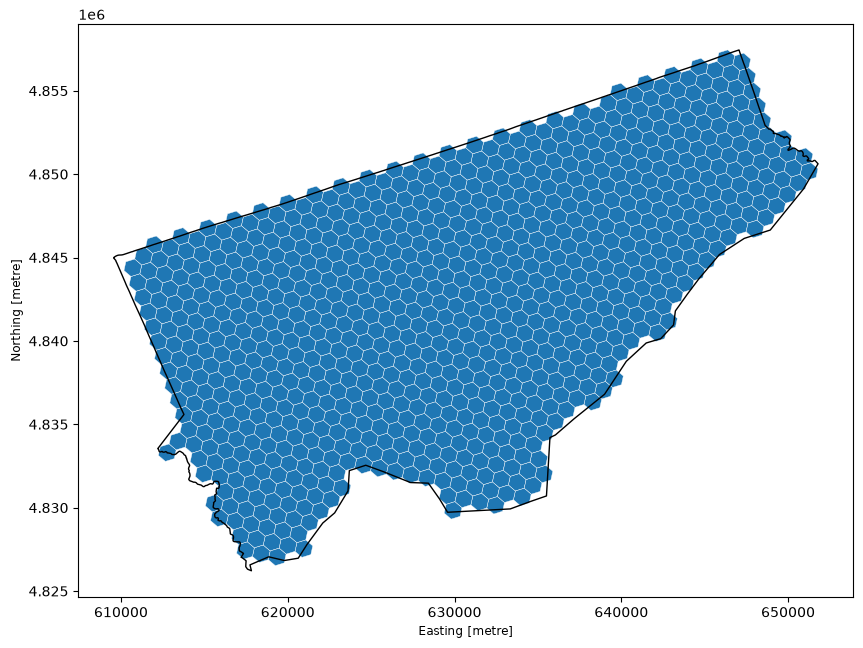

In [3]:
hexes_utm = hexes.to_crs(epsg=32617)
print("Average hexagon area:", round(hexes_utm.area.mean() / 1e6, 2), "km²")

ax = hexes_utm.plot(figsize=(10, 10), edgecolor="white", linewidth=0.3)
city_utm.boundary.plot(ax=ax, color="black", linewidth=1)

In [4]:
hexes_utm.to_file("../data/processed/hex_grid.gpkg", driver="GPKG")
print("Saved")

Saved
